In [7]:
import pandas as pd
df= pd.read_csv("online_Retail.csv")
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12.0,01-12-2009 07:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12.0,01-12-2009 07:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12.0,01-12-2009 07:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48.0,01-12-2009 07:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24.0,01-12-2009 07:45,1.25,13085.0,United Kingdom


In [8]:
df.shape

(122864, 8)

In [9]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122864 entries, 0 to 122863
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      122864 non-null  object 
 1   StockCode    122864 non-null  object 
 2   Description  121724 non-null  object 
 3   Quantity     122863 non-null  float64
 4   InvoiceDate  122863 non-null  object 
 5   Price        122863 non-null  float64
 6   Customer ID  91041 non-null   float64
 7   Country      122863 non-null  object 
dtypes: float64(3), object(5)
memory usage: 7.5+ MB


In [12]:
df.isnull()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
122859,False,False,False,False,False,False,False,False
122860,False,False,False,False,False,False,False,False
122861,False,False,False,False,False,False,False,False
122862,False,False,False,False,False,False,False,False


In [13]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
122859    False
122860    False
122861    False
122862    False
122863    False
Length: 122864, dtype: bool

In [14]:
df.describe()

,Quantity,Price,Customer ID
count,122863.000000,122863.000000,91041.000000
mean,10.734159,4.469694,15315.906130
std,106.085449,44.741361,1677.011192
min,-4200.000000,0.000000,12346.000000
25%,1.000000,1.250000,13931.000000
50%,3.000000,2.510000,15222.000000
75%,10.000000,4.300000,16792.000000
max,19152.000000,8985.600000,18287.000000


In [ ]:
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'])

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122864 entries, 0 to 122863
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      122864 non-null  object        
 1   StockCode    122864 non-null  object        
 2   Description  121724 non-null  object        
 3   Quantity     122863 non-null  float64       
 4   InvoiceDate  122863 non-null  datetime64[ns]
 5   Price        122863 non-null  float64       
 6   Customer ID  91041 non-null   float64       
 7   Country      122863 non-null  object        
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 7.5+ MB


In [17]:
df.duplicated().sum()

1315

In [19]:
df.isnull().sum()

Invoice            0
StockCode          0
Description     1140
Quantity           1
InvoiceDate        1
Price              1
Customer ID    31823
Country            1
dtype: int64

In [21]:
print("Negative quantities:",(df['Quantity']<0).sum())
print("Zero prices:",(df['Price']==0).sum())
print("Negative prices:",(df['Price']<0).sum())

Negative quantities: 3353
Zero prices: 1235
Negative prices: 0


In [22]:
df['Invoice'].astype(str).str.startswith('c').sum()

0

In [23]:
# Create a backup of the original dataset
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows with missing essential transaction details
df_clean = df_clean.dropna(
    subset=['Invoice', 'StockCode', 'Quantity', 'InvoiceDate', 'Price', 'Country']
)

# Remove rows with missing product descriptions
df_clean = df_clean.dropna(subset=['Description'])

# Check the new dataset size
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)


Original dataset: (122864, 8)
Cleaned dataset: (120408, 8)


In [24]:
df_clean.isnull().sum()

Invoice            0
StockCode          0
Description        0
Quantity           0
InvoiceDate        0
Price              0
Customer ID    30654
Country            0
dtype: int64

In [25]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 120408 entries, 0 to 122862
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      120408 non-null  object        
 1   StockCode    120408 non-null  object        
 2   Description  120408 non-null  object        
 3   Quantity     120408 non-null  float64       
 4   InvoiceDate  120408 non-null  datetime64[ns]
 5   Price        120408 non-null  float64       
 6   Customer ID  89754 non-null   float64       
 7   Country      120408 non-null  object        
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 8.3+ MB


In [26]:
# Check negative quantities
print("Negative quantities:",
      (df_clean['Quantity'] < 0).sum())

# Check zero prices
print("Zero prices:",
      (df_clean['Price'] == 0).sum())

# View negative quantity records
df_clean[df_clean['Quantity'] < 0].head(10)

Negative quantities: 2608
Zero prices: 95


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12.0,2009-01-12 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6.0,2009-01-12 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4.0,2009-01-12 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6.0,2009-01-12 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12.0,2009-01-12 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12.0,2009-01-12 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12.0,2009-01-12 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24.0,2009-01-12 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12.0,2009-01-12 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3.0,2009-01-12 10:44:00,4.25,17592.0,United Kingdom


In [27]:
df_clean['Revenue'] = (
    df_clean['Quantity'] * df_clean['Price']
)

df_clean[['Invoice', 'Description', 'Quantity',
          'Price', 'Revenue']].head(10)

,Invoice,Description,Quantity,Price,Revenue
0,489434,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12.0,6.95,83.4
1,489434,PINK CHERRY LIGHTS,12.0,6.75,81.0
2,489434,WHITE CHERRY LIGHTS,12.0,6.75,81.0
3,489434,"RECORD FRAME 7"" SINGLE SIZE",48.0,2.10,100.8
4,489434,STRAWBERRY CERAMIC TRINKET BOX,24.0,1.25,30.0
5,489434,PINK DOUGHNUT TRINKET POT,24.0,1.65,39.6
6,489434,SAVE THE PLANET MUG,24.0,1.25,30.0
7,489434,FANCY FONT HOME SWEET HOME DOORMAT,10.0,5.95,59.5
8,489435,CAT BOWL,12.0,2.55,30.6
9,489435,"DOG BOWL , CHASING BALL DESIGN",12.0,3.75,45.0


In [28]:
print("Total revenue:", df_clean['Revenue'].sum())

Total revenue: 2242535.438


In [29]:
print("Total Revenue:", df_clean['Revenue'].sum())
print("Total Transactions:", df_clean['Invoice'].nunique())
print("Unique Products:", df_clean['Description'].nunique())
print("Unique Countries:", df_clean['Country'].nunique())

Total Revenue: 2242535.438
Total Transactions: 5793
Unique Products: 3556
Unique Countries: 28


In [30]:
top_products = (
    df_clean.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
WHITE HANGING HEART T-LIGHT HOLDER    44210.35
DOTCOM POSTAGE                        41013.85
JUMBO BAG RED WHITE SPOTTY            20418.95
ASSORTED COLOUR BIRD ORNAMENT         15471.41
EDWARDIAN PARASOL BLACK               15341.44
RETRO SPOT CAKE STAND                 12930.51
EDWARDIAN PARASOL RED                 11958.34
KENSINGTON COFFEE SET                 11916.31
EDWARDIAN PARASOL NATURAL             11832.11
 WHITE CHERRY LIGHTS                  11775.56
Name: Revenue, dtype: float64

In [31]:
country_sales = (
    df_clean.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales

Country
United Kingdom    1904903.438
EIRE               112224.840
Netherlands         72772.250
Germany             36729.210
France              27898.520
Denmark             26163.040
Spain               11929.810
Sweden              11116.330
Greece               5932.030
Belgium              4656.540
Name: Revenue, dtype: float64

In [32]:
df_clean['Month'] = df_clean['InvoiceDate'].dt.to_period('M')

monthly_sales = df_clean.groupby('Month')['Revenue'].sum()

monthly_sales

Month
2009-01     53010.760
2009-02     62583.660
2009-03     68027.590
2009-04     40195.800
2009-05      9803.050
2009-06     24126.580
2009-07     44169.880
2009-08     43702.140
2009-09     40046.120
2009-10     43134.330
2009-11     38213.210
2009-12    329635.380
2010-01    422822.653
2010-02    385623.164
2010-03     55106.351
2010-04     67189.970
2010-05     67268.840
2010-06      8736.750
2010-07    108650.510
2010-08     82278.140
2010-09     38911.170
2010-10     59521.900
2010-11     76810.410
2010-12     72967.080
Freq: M, Name: Revenue, dtype: float64

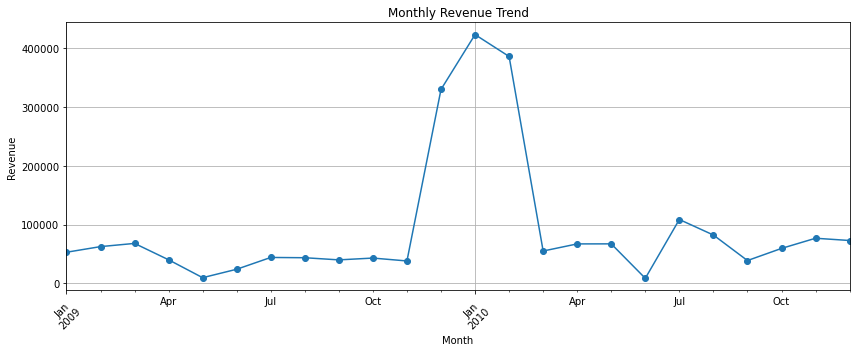

In [33]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind='line', marker='o', figsize=(12, 5))

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
top_products = (
    df_clean.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
WHITE HANGING HEART T-LIGHT HOLDER    44210.35
DOTCOM POSTAGE                        41013.85
JUMBO BAG RED WHITE SPOTTY            20418.95
ASSORTED COLOUR BIRD ORNAMENT         15471.41
EDWARDIAN PARASOL BLACK               15341.44
RETRO SPOT CAKE STAND                 12930.51
EDWARDIAN PARASOL RED                 11958.34
KENSINGTON COFFEE SET                 11916.31
EDWARDIAN PARASOL NATURAL             11832.11
 WHITE CHERRY LIGHTS                  11775.56
Name: Revenue, dtype: float64


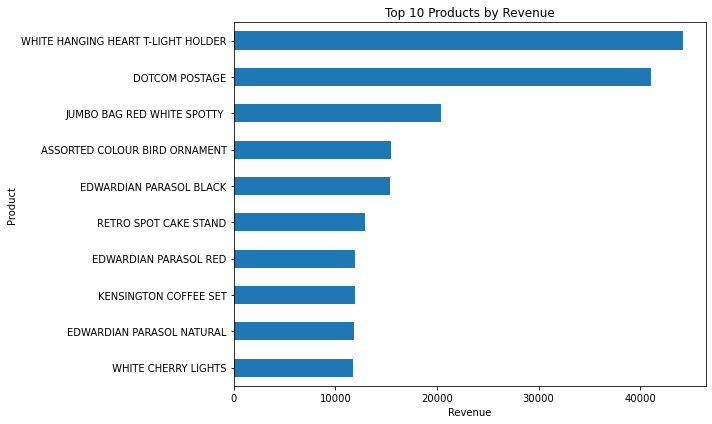

In [35]:
import matplotlib.pyplot as plt

top_products.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

In [36]:
country_sales = (
    df_clean.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_sales)

Country
United Kingdom    1904903.438
EIRE               112224.840
Netherlands         72772.250
Germany             36729.210
France              27898.520
Denmark             26163.040
Spain               11929.810
Sweden              11116.330
Greece               5932.030
Belgium              4656.540
Name: Revenue, dtype: float64


In [37]:
df_clean['Month'] = df_clean['InvoiceDate'].dt.to_period('M')

monthly_sales = df_clean.groupby('Month')['Revenue'].sum()

print(monthly_sales)

Month
2009-01     53010.760
2009-02     62583.660
2009-03     68027.590
2009-04     40195.800
2009-05      9803.050
2009-06     24126.580
2009-07     44169.880
2009-08     43702.140
2009-09     40046.120
2009-10     43134.330
2009-11     38213.210
2009-12    329635.380
2010-01    422822.653
2010-02    385623.164
2010-03     55106.351
2010-04     67189.970
2010-05     67268.840
2010-06      8736.750
2010-07    108650.510
2010-08     82278.140
2010-09     38911.170
2010-10     59521.900
2010-11     76810.410
2010-12     72967.080
Freq: M, Name: Revenue, dtype: float64


In [39]:
customer_sales = (
    df_clean.dropna(subset=['Customer ID'])
    .groupby('Customer ID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(customer_sales)

Customer ID
18102.0    108170.34
14156.0     79176.01
14646.0     71535.42
13694.0     56967.23
14911.0     27389.65
15311.0     24319.28
13902.0     23544.96
17850.0     19419.68
15061.0     19283.28
16029.0     18588.42
Name: Revenue, dtype: float64


In [40]:
# Keep transactions with a known Customer ID
rfm_data = df_clean.dropna(subset=['Customer ID']).copy()

# Check the data
print("Rows for RFM analysis:", rfm_data.shape[0])
print("Unique customers:", rfm_data['Customer ID'].nunique())


Rows for RFM analysis: 89754
Unique customers: 1988


In [41]:
import pandas as pd

# Set analysis date one day after the latest transaction
analysis_date = rfm_data['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = rfm_data.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (analysis_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Revenue', 'sum')
)

rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,247,11,127.05
12349.0,601,1,-24.15
12358.0,479,1,1429.83
12359.0,123,4,1098.43
12360.0,285,1,118.00


In [42]:
rfm.describe()

,Recency,Frequency,Monetary
count,1988.000000,1988.000000,1988.000000
mean,266.277163,2.649899,973.415703
std,159.344288,3.744772,3985.579250
min,1.000000,1.000000,-805.060000
25%,125.000000,1.000000,195.765000
50%,285.000000,2.000000,378.235000
75%,324.250000,3.000000,798.230000
max,691.000000,58.000000,108170.340000


In [43]:
# Score Recency: lower days means a better score
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Score Frequency: more invoices means a better score
rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Score Monetary: higher value means a better score
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm.head()


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
Customer ID,,,,,,
12346.0,247,11,127.05,4,5,1
12349.0,601,1,-24.15,1,1,1
12358.0,479,1,1429.83,1,1,5
12359.0,123,4,1098.43,5,5,5
12360.0,285,1,118.00,3,1,1


In [44]:
def segment_customer(row):
    if row['R_Score'] >= 4 and row['F_Score'] >= 4 and row['M_Score'] >= 4:
        return 'High Value'
    elif row['R_Score'] >= 3 and row['F_Score'] >= 3:
        return 'Loyal'
    elif row['R_Score'] <= 2:
        return 'At Risk'
    else:
        return 'Regular'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

print(rfm['Segment'].value_counts())


At Risk       795
Loyal         485
High Value    370
Regular       338
Name: Segment, dtype: int64


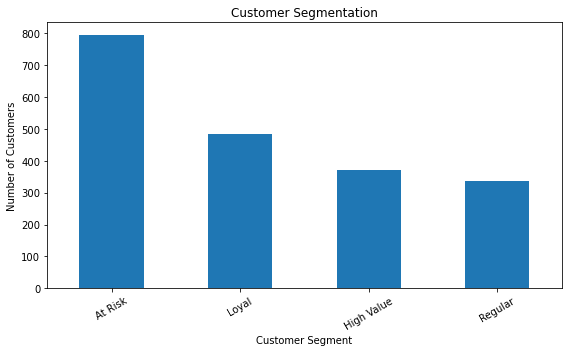

In [45]:
import matplotlib.pyplot as plt

rfm['Segment'].value_counts().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Customer Segmentation')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [46]:
# Save cleaned data
df_clean.to_csv("cleaned_retail_data.csv", index=False)

# Save customer segmentation results
rfm.to_csv("customer_rfm_segments.csv")

print("Files saved successfully!")

Files saved successfully!


In [47]:
print(rfm['Segment'].value_counts())

At Risk       795
Loyal         485
High Value    370
Regular       338
Name: Segment, dtype: int64


In [48]:
import os

print("Cleaned dataset exists:",
      os.path.exists("cleaned_retail_data.csv"))

print("RFM results exist:",
      os.path.exists("customer_rfm_segments.csv"))

Cleaned dataset exists: True
RFM results exist: True


In [52]:
# Create Strategic Priority Score
rfm['Strategic_Priority_Score'] = (
    (rfm['R_Score'] * 0.30) +
    (rfm['F_Score'] * 0.30) +
    (rfm['M_Score'] * 0.40)
).round(2)

# Rank customers by priority score
rfm['Priority_Rank'] = (
    rfm['Strategic_Priority_Score']
    .rank(method='dense', ascending=False)
    .astype(int)
)

# Display the top 10 priority customers
priority_customers = rfm.sort_values(
    'Strategic_Priority_Score',
    ascending=False
).head(10)

print(priority_customers[
    ['Recency', 'Frequency', 'Monetary',
     'Segment', 'Strategic_Priority_Score', 'Priority_Rank']
])

             Recency  Frequency  Monetary     Segment  \
Customer ID                                             
13694.0           64         37  56967.23  High Value   
17920.0           64          9   6490.91  High Value   
12709.0           33          9   3272.82  High Value   
14527.0           31         31  10679.58  High Value   
13854.0           92          6   1078.57  High Value   
15601.0           64          8   3427.24  High Value   
13081.0           62          5  10059.36  High Value   
13078.0           62         16   4617.05  High Value   
15633.0            2          6   1686.14  High Value   
13093.0           31         18   7779.12  High Value   

             Strategic_Priority_Score  Priority_Rank  
Customer ID                                           
13694.0                           5.0              1  
17920.0                           5.0              1  
12709.0                           5.0              1  
14527.0                           5.0   

In [53]:
# Normalize the actual RFM values to a 0–1 scale
rfm['R_Normalized'] = (
    1 - (rfm['Recency'] - rfm['Recency'].min()) /
    (rfm['Recency'].max() - rfm['Recency'].min())
)

rfm['F_Normalized'] = (
    (rfm['Frequency'] - rfm['Frequency'].min()) /
    (rfm['Frequency'].max() - rfm['Frequency'].min())
)

rfm['M_Normalized'] = (
    (rfm['Monetary'] - rfm['Monetary'].min()) /
    (rfm['Monetary'].max() - rfm['Monetary'].min())
)

# Calculate the improved priority score out of 100
rfm['Strategic_Priority_Score'] = (
    30 * rfm['R_Normalized'] +
    30 * rfm['F_Normalized'] +
    40 * rfm['M_Normalized']
).round(2)

# Display the top 10 customers
print(
    rfm.sort_values(
        'Strategic_Priority_Score', ascending=False
    )[
        ['Recency', 'Frequency', 'Monetary',
         'Segment', 'Strategic_Priority_Score']
    ].head(10)
)

             Recency  Frequency   Monetary     Segment  \
Customer ID                                              
18102.0            3         26  108170.34  High Value   
14156.0           33         42   79176.01  High Value   
14911.0            1         58   27389.65  High Value   
14646.0            1         24   71535.42  High Value   
13694.0           64         37   56967.23  High Value   
15311.0           31         48   24319.28  High Value   
14606.0            2         41    5444.83  High Value   
17841.0            3         36    7537.13  High Value   
14527.0           31         31   10679.58  High Value   
17850.0          245         42   19419.68  High Value   

             Strategic_Priority_Score  
Customer ID                            
18102.0                         83.07  
14156.0                         79.55  
14911.0                         70.35  
14646.0                         68.66  
13694.0                         67.41  
15311.0                

In [54]:
import numpy as np

rfm['Priority_Category'] = np.select(
    [
        rfm['Strategic_Priority_Score'] >= 70,
        rfm['Strategic_Priority_Score'] >= 40
    ],
    [
        'High Priority',
        'Medium Priority'
    ],
    default='Low Priority'
)

print(rfm['Priority_Category'].value_counts())

Low Priority       1966
Medium Priority      19
High Priority         3
Name: Priority_Category, dtype: int64


In [55]:
priority_summary = rfm.groupby('Priority_Category').agg(
    Total_Customers=('Strategic_Priority_Score', 'count'),
    Average_Priority_Score=('Strategic_Priority_Score', 'mean'),
    Total_Customer_Revenue=('Monetary', 'sum')
).round(2)

print(priority_summary)

                   Total_Customers  Average_Priority_Score  \
Priority_Category                                            
High Priority                    3                   77.66   
Low Priority                  1966                   19.63   
Medium Priority                 19                   48.18   

                   Total_Customer_Revenue  
Priority_Category                          
High Priority                   214736.00  
Low Priority                   1421545.04  
Medium Priority                 298869.38  


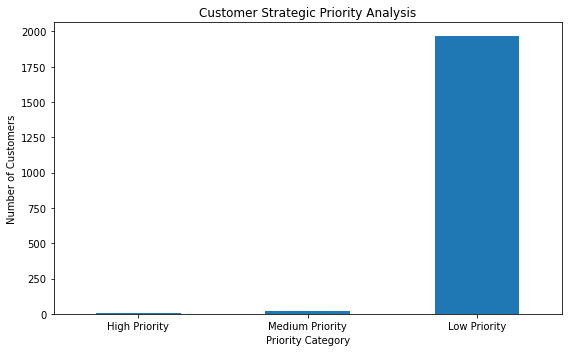

In [56]:
import matplotlib.pyplot as plt

priority_counts = rfm['Priority_Category'].value_counts().reindex(
    ['High Priority', 'Medium Priority', 'Low Priority'],
    fill_value=0
)

priority_counts.plot(kind='bar', figsize=(8, 5))

plt.title('Customer Strategic Priority Analysis')
plt.xlabel('Priority Category')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()